<a href="https://colab.research.google.com/github/santos-robsonedu/Experimento_aumento_de_margem/blob/main/Teste_de_entropia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import entropy
from scipy.stats import binomtest

In [ ]:
# Lendo o arquivo
df = pd.read_excel('BRA.xlsx')
df.sample(5)

NameError: name 'pd' is not defined

In [ ]:
# Selecionando apenas as colunas necessárias
df = df[['Date','Home','Away','Res','AvgCH','AvgCD','AvgCA']].copy()
df.sample(5)

,Date,Home,Away,Res,AvgCH,AvgCD,AvgCA
481,2013-08-04,Criciuma,Corinthians,A,3.16,3.19,2.23
4934,2024-12-08,Cuiaba,Vasco,A,3.52,3.16,2.19
3109,2020-09-06,Internacional,Bahia,D,1.55,3.81,6.28
3338,2021-01-20,Gremio,Atletico-MG,D,2.46,3.27,2.83
3550,2021-08-01,Atletico-MG,Athletico-PR,H,1.68,3.57,5.39


In [ ]:
# Visualizando a situação das colunas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5149 entries, 0 to 5148
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5149 non-null   datetime64[ns]
 1   Home    5149 non-null   object        
 2   Away    5149 non-null   object        
 3   Res     5148 non-null   object        
 4   AvgCH   5149 non-null   float64       
 5   AvgCD   5149 non-null   float64       
 6   AvgCA   5149 non-null   float64       
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 281.7+ KB


In [ ]:
# Buscando o jogo que não tem resultado
df.loc[df['Res'].isnull()]
# O jogo da chapecoense foi cancelado
# Excluindo esse jogo dos dados
df.dropna(inplace = True)
df.loc[df['Res'].isnull()]

,Date,Home,Away,Res,AvgCH,AvgCD,AvgCA


In [ ]:
# Visualizando o estado dos dados
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5148 entries, 0 to 5148
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5148 non-null   datetime64[ns]
 1   Home    5148 non-null   object        
 2   Away    5148 non-null   object        
 3   Res     5148 non-null   object        
 4   AvgCH   5148 non-null   float64       
 5   AvgCD   5148 non-null   float64       
 6   AvgCA   5148 non-null   float64       
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 321.8+ KB


In [ ]:
# Visualizando as estatísticas em busca de inconsistências
df.describe()

,Date,AvgCH,AvgCD,AvgCA
count,5148,5148.000000,5148.000000,5148.000000
mean,2018-12-07 06:03:04.615384576,2.235332,3.484359,4.333118
min,2012-05-19 00:00:00,1.070000,2.510000,1.150000
25%,2015-07-26 00:00:00,1.670000,3.140000,2.860000
50%,2018-10-21 00:00:00,2.030000,3.300000,3.760000
75%,2022-05-21 00:00:00,2.540000,3.660000,5.282500
max,2025-09-01 00:00:00,20.230000,10.820000,26.580000
std,NaN,0.882157,0.572213,2.131644


In [ ]:
# Ordenando o dataframe pela coluna 'Date'
df = df.sort_values(by='Date').reset_index(drop=True)
df

,Date,Home,Away,Res,AvgCH,AvgCD,AvgCA
0,2012-05-19,Palmeiras,Portuguesa,D,1.69,3.50,4.90
1,2012-05-19,Sport Recife,Flamengo RJ,D,2.59,3.23,2.58
2,2012-05-20,Figueirense,Nautico,H,1.59,3.67,5.64
3,2012-05-20,Botafogo RJ,Sao Paulo,H,2.35,3.26,2.84
4,2012-05-20,Corinthians,Fluminense,A,1.89,3.33,3.89
...,...,...,...,...,...,...,...
5143,2025-08-31,Cruzeiro,Sao Paulo,H,1.91,3.19,4.37
5144,2025-08-31,Flamengo RJ,Gremio,D,1.22,5.81,13.13
5145,2025-08-31,Vitoria,Atletico-MG,H,3.25,3.01,2.34
5146,2025-09-01,Internacional,Fortaleza,H,1.62,3.81,5.36


In [ ]:
# 1. Converte a coluna 'Date' para o tipo string
# 2. Acessa os métodos de string com .str
# 3. Calcula o comprimento de cada string com .len()
# 4. Conta a frequência de cada comprimento com .value_counts()

date_char_counts = df['Date'].astype(str).str.len().value_counts()

print(date_char_counts)

Date
10    5148
Name: count, dtype: int64


In [ ]:
# Verificando a consistência no nome dos times
df['Home'].sort_values().unique()

array(['America MG', 'Athletico-PR', 'Atletico GO', 'Atletico-MG', 'Avai',
       'Bahia', 'Botafogo RJ', 'Bragantino', 'CSA', 'Ceara',
       'Chapecoense-SC', 'Corinthians', 'Coritiba', 'Criciuma',
       'Cruzeiro', 'Cuiaba', 'Figueirense', 'Flamengo RJ', 'Fluminense',
       'Fortaleza', 'Goias', 'Gremio', 'Internacional', 'Joinville',
       'Juventude', 'Mirassol', 'Nautico', 'Palmeiras', 'Parana',
       'Ponte Preta', 'Portuguesa', 'Santa Cruz', 'Santos', 'Sao Paulo',
       'Sport Recife', 'Vasco', 'Vitoria'], dtype=object)

In [ ]:
# Verificando a consistência no nome dos times
df['Away'].sort_values().unique()

array(['America MG', 'Athletico-PR', 'Atletico GO', 'Atletico-MG', 'Avai',
       'Bahia', 'Botafogo RJ', 'Bragantino', 'CSA', 'Ceara',
       'Chapecoense-SC', 'Corinthians', 'Coritiba', 'Criciuma',
       'Cruzeiro', 'Cuiaba', 'Figueirense', 'Flamengo RJ', 'Fluminense',
       'Fortaleza', 'Goias', 'Gremio', 'Internacional', 'Joinville',
       'Juventude', 'Mirassol', 'Nautico', 'Palmeiras', 'Parana',
       'Ponte Preta', 'Portuguesa', 'Santa Cruz', 'Santos', 'Sao Paulo',
       'Sport Recife', 'Vasco', 'Vitoria'], dtype=object)

In [ ]:
# Etapa 1: Definir a paleta de cores padrão para os resultados
# Este dicionário pode ser reutilizado em todos os gráficos do notebook
cores_resultados = {
    'H': 'seagreen',  # Verde para vitória da casa
    'D': 'silver',    # Cinza para empate
    'A': 'royalblue'  # Azul para vitória do visitante
}

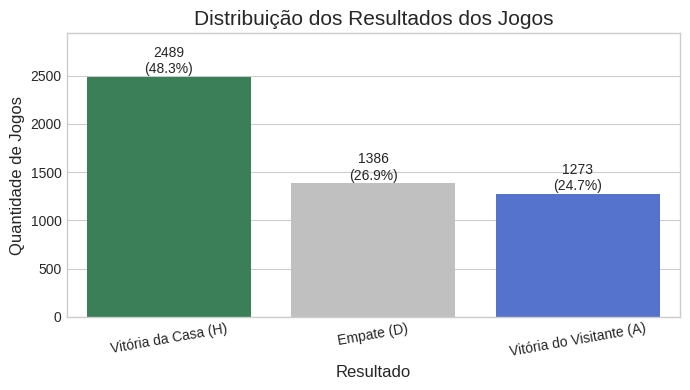

In [ ]:
# Etapa 2: Preparar os dados para o gráfico
resultado_counts = df['Res'].value_counts()
label_map = {
    'H': 'Vitória da Casa (H)',
    'D': 'Empate (D)',
    'A': 'Vitória do Visitante (A)'
}
resultado_counts.index = resultado_counts.index.map(label_map)

# --- NOVA ETAPA: Calcular o total de jogos ---
total_jogos = len(df) # Ou resultado_counts.sum()

# Etapa 3: Criar a figura e o gráfico
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=resultado_counts.index,
    y=resultado_counts.values,
    palette=cores_resultados.values(),
    hue=resultado_counts.index,
    legend=False
)

# --- ETAPA 4 ATUALIZADA: Adicionar rótulos com contagem e percentual ---
for patch in ax.patches:
    # Pega a altura (contagem) da barra
    height = patch.get_height()

    # Calcula o percentual
    percentage = (height / total_jogos) * 100

    # Define a posição do texto
    x_pos = patch.get_x() + patch.get_width() / 2.0
    y_pos = height + 5 # Ajusta a posição y para o novo rótulo

    # Cria o texto do rótulo com duas linhas: contagem e percentual
    # \n cria uma quebra de linha
    label_text = f'{int(height)}\n({percentage:.1f}%)'

    ax.text(x=x_pos,
            y=y_pos,
            s=label_text,
            ha='center',
            va='bottom',
            fontsize=10) # Ajusta o tamanho da fonte se necessário

# Etapa 5: Melhorar o visual com títulos e rótulos
plt.title('Distribuição dos Resultados dos Jogos', fontsize=15)
plt.xlabel('Resultado', fontsize=12)
plt.ylabel('Quantidade de Jogos', fontsize=12)
# Aumentamos um pouco mais o limite do eixo Y para dar espaço ao rótulo de duas linhas
plt.ylim(0, resultado_counts.max() * 1.18)

# Etapa 6: Exibir o gráfico
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [ ]:
# Define uma paleta de cores consistente, agora usando os novos rótulos como chaves
cores_odds = {
    'Casa (H)': 'seagreen',
    'Empate (D)': 'silver',
    'Visitante (A)': 'royalblue'
}

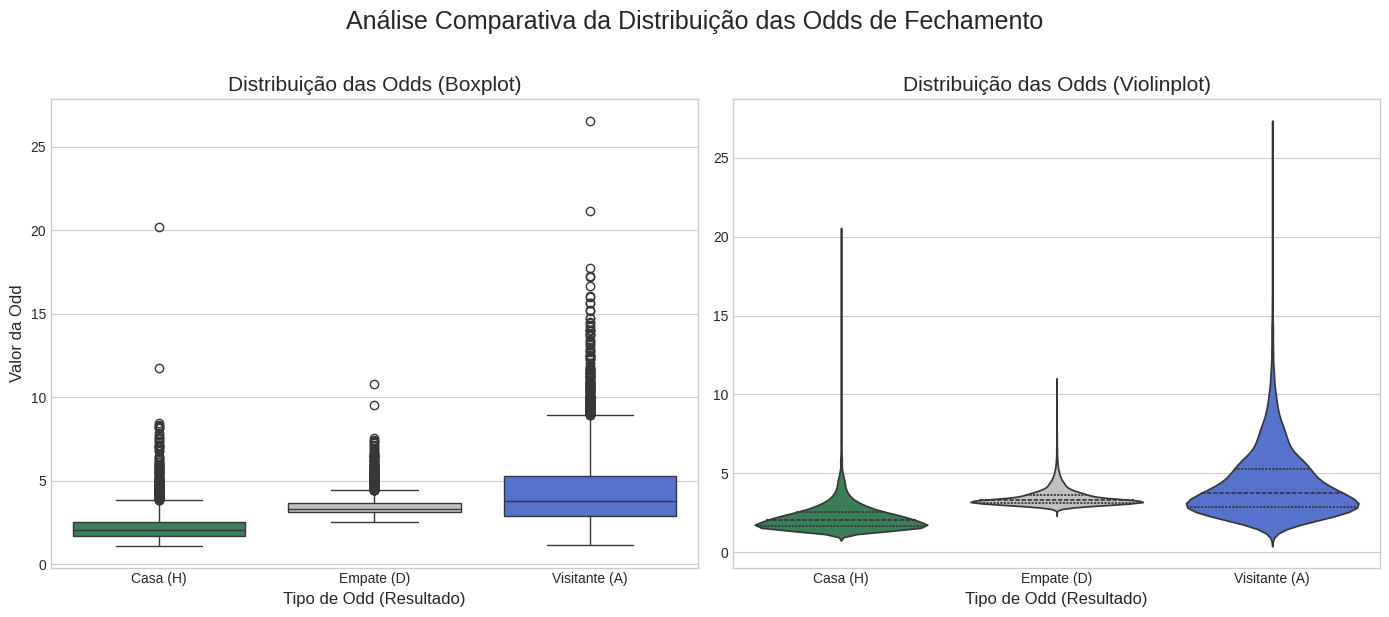

In [ ]:
# --- Preparação dos Dados (Etapa Principal) ---

# Seleciona as colunas de odds
df_odds = df[['AvgCH', 'AvgCD', 'AvgCA']]

# "Derrete" o DataFrame para o formato longo
df_odds = df_odds.melt(
    var_name='Tipo de Odd',
    value_name='Valor da Odd'
)

# --- AQUI ESTÁ A CORREÇÃO ---
# Mapeia os nomes das colunas para os rótulos desejados
label_map = {
    'AvgCH': 'Casa (H)',
    'AvgCD': 'Empate (D)',
    'AvgCA': 'Visitante (A)'
}
df_odds['Tipo de Odd'] = df_odds['Tipo de Odd'].map(label_map)
# --------------------------------

# --- Criação dos Gráficos (Agora mais limpo) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Gráfico 1: Boxplot ---
sns.boxplot(
    data=df_odds,
    x='Tipo de Odd',
    y='Valor da Odd',
    ax=axes[0],
    palette=cores_odds,
    hue='Tipo de Odd',
    legend=False,
    order=['Casa (H)', 'Empate (D)', 'Visitante (A)'] # Garante a ordem correta no gráfico
)
axes[0].set_title('Distribuição das Odds (Boxplot)', fontsize=15)
axes[0].set_xlabel('Tipo de Odd (Resultado)', fontsize=12)
axes[0].set_ylabel('Valor da Odd', fontsize=12)
# A linha set_xticklabels() não é mais necessária!

# --- Gráfico 2: Violinplot ---
sns.violinplot(
    data=df_odds,
    x='Tipo de Odd',
    y='Valor da Odd',
    ax=axes[1],
    palette=cores_odds,
    hue='Tipo de Odd',
    legend=False,
    inner='quartile',
    order=['Casa (H)', 'Empate (D)', 'Visitante (A)'] # Garante a ordem correta
)
axes[1].set_title('Distribuição das Odds (Violinplot)', fontsize=15)
axes[1].set_xlabel('Tipo de Odd (Resultado)', fontsize=12)
axes[1].set_ylabel('') # Remove o rótulo Y
# A linha set_xticklabels() não é mais necessária!


# Título geral para a figura
plt.suptitle('Análise Comparativa da Distribuição das Odds de Fechamento', fontsize=18, y=1.02)

# Ajusta o layout e exibe
plt.tight_layout()
plt.show()

Número original de registros: 15444
Número de registros sem outliers: 14686
Total de outliers removidos: 758


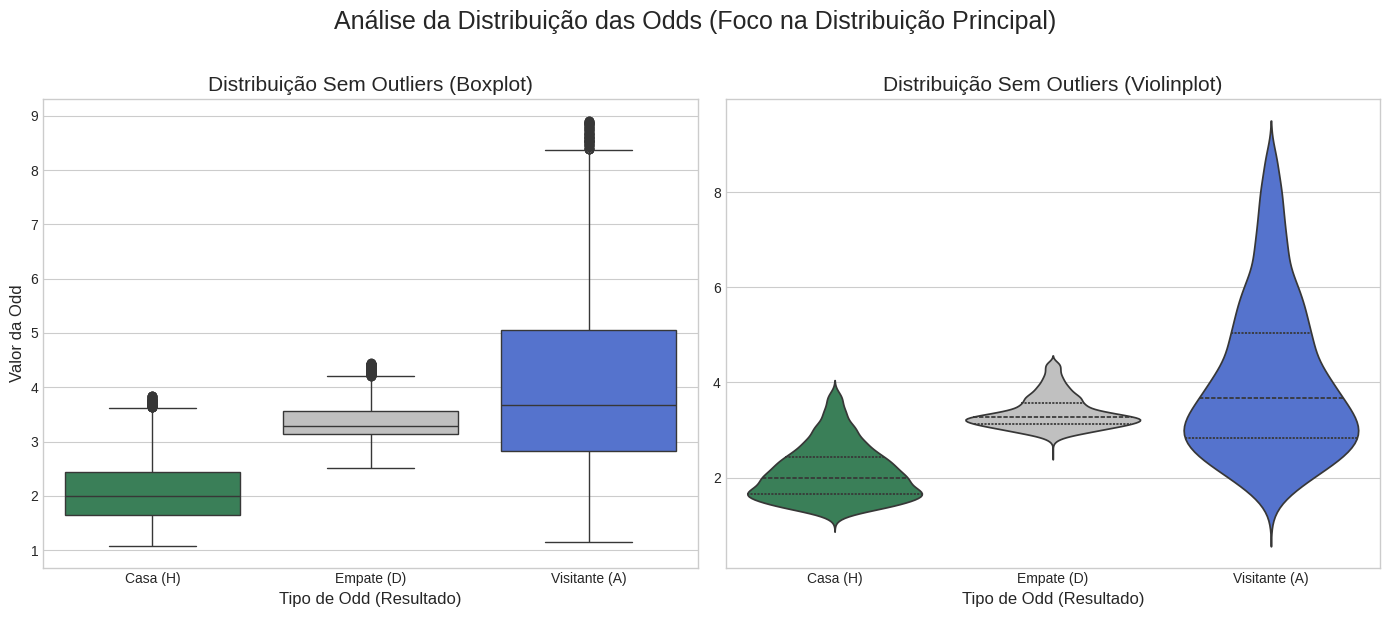

In [ ]:
# --- Preparação dos Dados (Mesmo código de antes) ---
df_odds = df[['AvgCH', 'AvgCD', 'AvgCA']].melt(
    var_name='Tipo de Odd',
    value_name='Valor da Odd'
)
label_map = {
    'AvgCH': 'Casa (H)',
    'AvgCD': 'Empate (D)',
    'AvgCA': 'Visitante (A)'
}
df_odds['Tipo de Odd'] = df_odds['Tipo de Odd'].map(label_map)

# --- ETAPA 1: Calcular os limites para remover outliers por categoria ---
# Vamos agrupar por 'Tipo de Odd' para calcular Q1, Q3 e IQR para cada um
Q1 = df_odds.groupby('Tipo de Odd')['Valor da Odd'].quantile(0.25)
Q3 = df_odds.groupby('Tipo de Odd')['Valor da Odd'].quantile(0.75)
IQR = Q3 - Q1

# Calcula os limites superior e inferior
limite_superior = Q3 + 1.5 * IQR
limite_inferior = Q1 - 1.5 * IQR

# Transforma os limites em um DataFrame para facilitar a junção
limites_df = pd.DataFrame({
    'Limite_Superior': limite_superior,
    'Limite_Inferior': limite_inferior
}).reset_index()

# Junta os limites de volta ao DataFrame de odds
df_odds_com_limites = pd.merge(df_odds, limites_df, on='Tipo de Odd')

# --- ETAPA 2: Filtrar os dados ---
# Cria uma condição booleana para manter apenas os dados dentro dos limites
dentro_dos_limites = (
    (df_odds_com_limites['Valor da Odd'] <= df_odds_com_limites['Limite_Superior']) &
    (df_odds_com_limites['Valor da Odd'] >= df_odds_com_limites['Limite_Inferior'])
)

# Cria o novo DataFrame sem os outliers
df_odds_sem_outliers = df_odds_com_limites[dentro_dos_limites]

print(f"Número original de registros: {len(df_odds)}")
print(f"Número de registros sem outliers: {len(df_odds_sem_outliers)}")
print(f"Total de outliers removidos: {len(df_odds) - len(df_odds_sem_outliers)}")


# --- ETAPA 3: Gerar os novos gráficos com os dados filtrados ---
# Paleta de cores (mesma de antes)
cores_odds = {
    'Casa (H)': 'seagreen',
    'Empate (D)': 'silver',
    'Visitante (A)': 'royalblue'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Gráfico 1: Boxplot (sem outliers) ---
sns.boxplot(
    data=df_odds_sem_outliers,
    x='Tipo de Odd',
    y='Valor da Odd',
    ax=axes[0],
    palette=cores_odds,
    hue='Tipo de Odd',
    legend=False,
    order=['Casa (H)', 'Empate (D)', 'Visitante (A)']
)
axes[0].set_title('Distribuição Sem Outliers (Boxplot)', fontsize=15)
axes[0].set_xlabel('Tipo de Odd (Resultado)', fontsize=12)
axes[0].set_ylabel('Valor da Odd', fontsize=12)

# --- Gráfico 2: Violinplot (sem outliers) ---
sns.violinplot(
    data=df_odds_sem_outliers,
    x='Tipo de Odd',
    y='Valor da Odd',
    ax=axes[1],
    palette=cores_odds,
    hue='Tipo de Odd',
    legend=False,
    inner='quartile',
    order=['Casa (H)', 'Empate (D)', 'Visitante (A)']
)
axes[1].set_title('Distribuição Sem Outliers (Violinplot)', fontsize=15)
axes[1].set_xlabel('Tipo de Odd (Resultado)', fontsize=12)
axes[1].set_ylabel('')

plt.suptitle('Análise da Distribuição das Odds (Foco na Distribuição Principal)', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

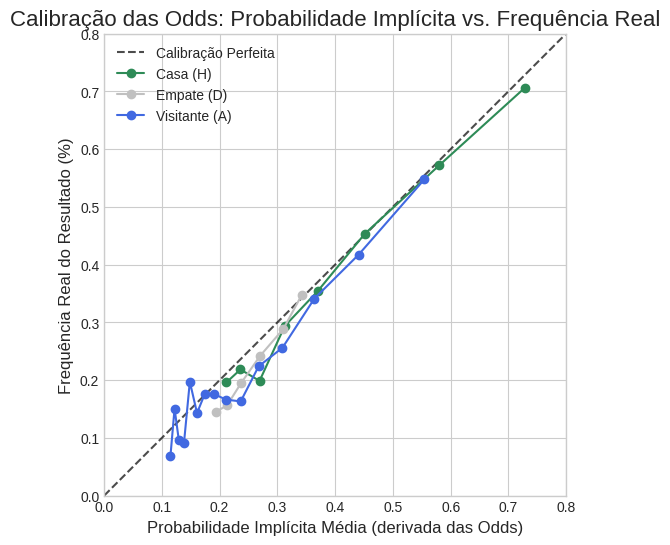

In [ ]:
# --- ETAPA 1: Preparar os dados ---
# Criar um DataFrame de trabalho com as colunas necessárias
df_analise = df[['Res', 'AvgCH', 'AvgCD', 'AvgCA']].copy()

# Calcular a probabilidade implícita para cada resultado
# (Ignorando a margem da casa de apostas por enquanto para simplificar)
df_analise['ProbH'] = 1 / df_analise['AvgCH']
df_analise['ProbD'] = 1 / df_analise['AvgCD']
df_analise['ProbA'] = 1 / df_analise['AvgCA']

# --- ETAPA 2: Criar as faixas (bins) de odds ---
# Vamos criar faixas de 0.25 em 0.25 para as odds
bins = np.arange(1, 10, 0.5) # Bins de 1.0 a 10.0, com passo de 0.5
labels = [f'{i:.2f}-{i+0.5:.2f}' for i in bins[:-1]]

# Dicionário para guardar os resultados da análise
resultados_calibracao = {}

# Dicionário para iterar sobre cada tipo de resultado
outcomes = {
    'H': 'AvgCH',
    'D': 'AvgCD',
    'A': 'AvgCA'
}

# --- ETAPA 3: Calcular a frequência real vs. a probabilidade implícita para cada faixa ---
for outcome_char, odd_col in outcomes.items():
    # Cria uma coluna temporária com as faixas de odds
    df_analise['bin'] = pd.cut(df_analise[odd_col], bins=bins, labels=labels, right=False)

    # Agrupa por faixa
    grouped = df_analise.groupby('bin', observed=True)

    # Calcula a probabilidade implícita média e a frequência real para cada faixa
    calibracao = grouped.agg(
        total_jogos=('Res', 'count'),
        prob_implicita_media=(f'Prob{outcome_char}', 'mean'),
        # A média de uma coluna booleana é a frequência! (True=1, False=0)
        frequencia_real=('Res', lambda x: (x == outcome_char).mean())
    ).reset_index()

    # Filtra faixas com poucos jogos para ter uma estatística mais robusta
    resultados_calibracao[outcome_char] = calibracao[calibracao['total_jogos'] > 50]

# --- ETAPA 4: Visualizar os resultados ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(8, 6))

# Linha de calibração perfeita (onde y=x)
plt.plot([0, 1], [0, 1], 'k--', label='Calibração Perfeita', alpha=0.7)

# Plotar os resultados para cada tipo de aposta
cores = {'H': 'seagreen', 'D': 'silver', 'A': 'royalblue'}
nomes = {'H': 'Casa (H)', 'D': 'Empate (D)', 'A': 'Visitante (A)'}

for outcome_char, df_resultado in resultados_calibracao.items():
    plt.plot(
        df_resultado['prob_implicita_media'],
        df_resultado['frequencia_real'],
        marker='o',
        linestyle='-',
        label=nomes[outcome_char],
        color=cores[outcome_char]
    )

# Configurações do gráfico
plt.title('Calibração das Odds: Probabilidade Implícita vs. Frequência Real', fontsize=16)
plt.xlabel('Probabilidade Implícita Média (derivada das Odds)', fontsize=12)
plt.ylabel('Frequência Real do Resultado (%)', fontsize=12)
plt.legend()
plt.xlim(0, 0.8) # Limita o eixo X para melhor visualização
plt.ylim(0, 0.8)
plt.gca().set_aspect('equal', adjustable='box') # Deixa os eixos com a mesma escala
plt.show()

# Análise de acordo com a entropia

Estatísticas da Entropia:
count    5148.000000
mean        1.468157
std         0.130225
min         0.641514
25%         1.408526
50%         1.518364
75%         1.567640
max         1.584909
Name: entropy, dtype: float64

--- Limites Sugeridos (Baseado em Quartis) ---
Baixa Entropia: Abaixo de 1.409
Média Entropia: Entre 1.409 e 1.568
Alta Entropia: Acima de 1.568


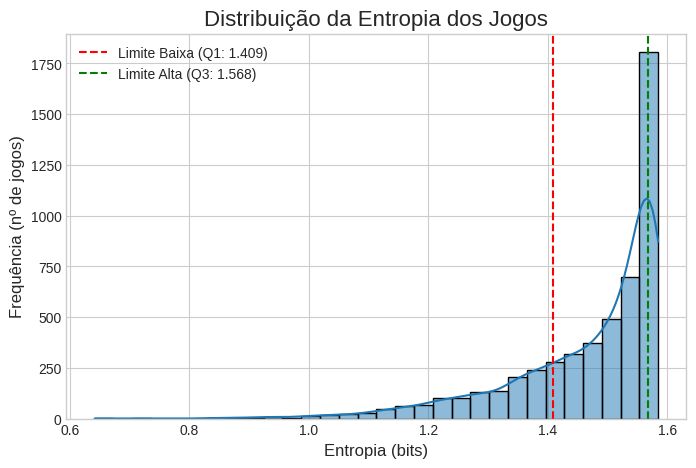

In [ ]:
# --- ETAPA 1: Calcular a Entropia ---

# Seleciona as colunas de odds
df_probs = df[['AvgCH', 'AvgCD', 'AvgCA']].copy()

# Converte odds para probabilidades implícitas
df_probs = 1 / df_probs

# Normaliza as probabilidades para que a soma seja 1 em cada linha
# Isso remove a margem da casa de apostas e é crucial para o cálculo da entropia
df_probs_normalized = df_probs.div(df_probs.sum(axis=1), axis=0)

# Calcula a entropia para cada jogo (linha) usando a base 2
# Adiciona o resultado como uma nova coluna no DataFrame original
df['entropy'] = entropy(df_probs_normalized.T, base=2)


# --- ETAPA 2: Definir os Limites Usando Quantis ---
# O método .describe() já nos dá os quartis (25%, 50%, 75%)
entropy_stats = df['entropy'].describe()
print("Estatísticas da Entropia:")
print(entropy_stats)

# Define os limites com base nos quartis
limite_baixa_entropia = entropy_stats['25%']
limite_alta_entropia = entropy_stats['75%']

print(f"\n--- Limites Sugeridos (Baseado em Quartis) ---")
print(f"Baixa Entropia: Abaixo de {limite_baixa_entropia:.3f}")
print(f"Média Entropia: Entre {limite_baixa_entropia:.3f} e {limite_alta_entropia:.3f}")
print(f"Alta Entropia: Acima de {limite_alta_entropia:.3f}")


# --- ETAPA 3: Visualizar a Distribuição com um Histograma ---
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='entropy', kde=True, bins=30)

# Adiciona linhas verticais para os limites que encontramos
plt.axvline(limite_baixa_entropia, color='red', linestyle='--', label=f'Limite Baixa (Q1: {limite_baixa_entropia:.3f})')
plt.axvline(limite_alta_entropia, color='green', linestyle='--', label=f'Limite Alta (Q3: {limite_alta_entropia:.3f})')

plt.title('Distribuição da Entropia dos Jogos', fontsize=16)
plt.xlabel('Entropia (bits)', fontsize=12)
plt.ylabel('Frequência (nº de jogos)', fontsize=12)
plt.legend()
plt.show()

In [ ]:
# --- ETAPA 1: Definir os limites e os rótulos ---

# Os limites já foram calculados no passo anterior
# Vamos apenas colocá-los em variáveis para clareza
limite_baixa = df['entropy'].quantile(0.25) # Primeiro quartil (Q1)
limite_alta = df['entropy'].quantile(0.75)  # Terceiro quartil (Q3)

# Para usar o pd.cut(), precisamos de uma lista com as "fronteiras" das faixas.
# Usamos -np.inf e np.inf para garantir que todos os valores sejam incluídos.
bins = [-np.inf, limite_baixa, limite_alta, np.inf]

# Definimos os nomes para cada uma das faixas criadas pelos limites acima
labels = ['Baixa', 'Média', 'Alta']


# --- ETAPA 2: Criar a nova coluna ---
# Usamos pd.cut para aplicar os limites e rótulos à coluna 'entropy'
df['faixa_entropia'] = pd.cut(df['entropy'], bins=bins, labels=labels)


# --- ETAPA 3: Verificar o resultado ---

# 1. Olhar as primeiras linhas para ver a nova coluna em ação
print("Visualização do DataFrame com a nova coluna:")
print(df[['entropy', 'faixa_entropia']].head())

print("\n" + "="*40 + "\n")

# 2. Contar quantos jogos caíram em cada categoria
# Isso é um ótimo teste para ver se a divisão 25% / 50% / 25% funcionou
print("Distribuição dos jogos por faixa de entropia:")
print(df['faixa_entropia'].value_counts())

Visualização do DataFrame com a nova coluna:
    entropy faixa_entropia
0  1.437348          Média
1  1.577430           Alta
2  1.383406          Baixa
3  1.571846           Alta
4  1.510293          Média


Distribuição dos jogos por faixa de entropia:
faixa_entropia
Média    2574
Baixa    1287
Alta     1287
Name: count, dtype: int64


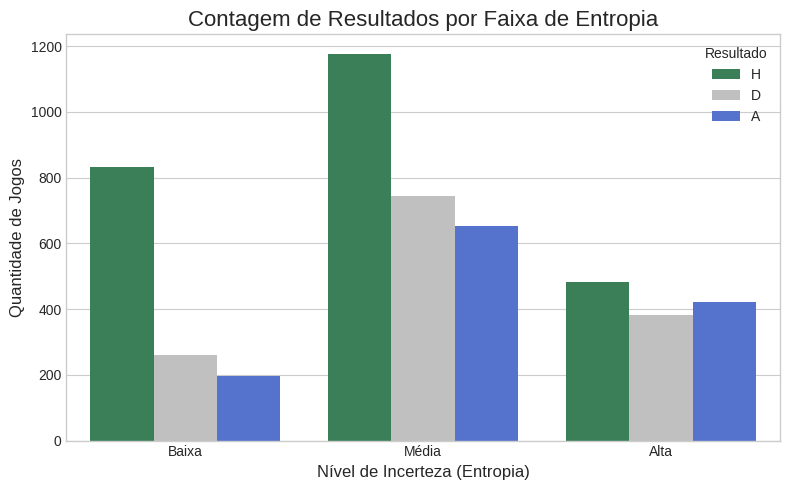

In [ ]:
# Reutilizando nossa paleta de cores para consistência
cores_resultados = {
    'H': 'seagreen',
    'D': 'silver',
    'A': 'royalblue'
}

# --- Preparação dos Dados ---
# Agrupamos por faixa de entropia e contamos os resultados
counts_por_faixa = df.groupby('faixa_entropia', observed=True)['Res'].value_counts().reset_index(name='count')

# --- Plotagem ---
plt.figure(figsize=(8, 5))
sns.barplot(
    data=counts_por_faixa,
    x='faixa_entropia',
    y='count',
    hue='Res',
    palette=cores_resultados,
    order=['Baixa', 'Média', 'Alta'], # Garante a ordem correta no eixo X
    hue_order=['H', 'D', 'A']        # Garante a ordem correta na legenda
)

plt.title('Contagem de Resultados por Faixa de Entropia', fontsize=16)
plt.xlabel('Nível de Incerteza (Entropia)', fontsize=12)
plt.ylabel('Quantidade de Jogos', fontsize=12)
plt.legend(title='Resultado')
plt.tight_layout()
plt.show()

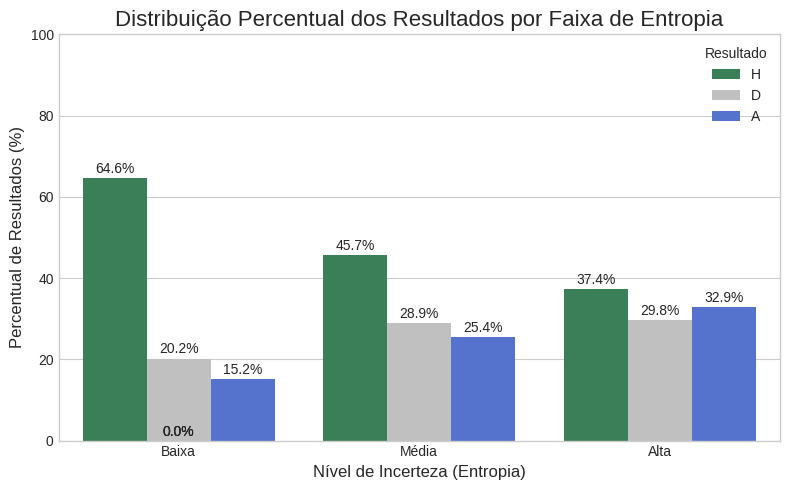

In [ ]:
# --- Preparação dos Dados (aqui está a diferença) ---
# Usamos normalize=True para obter a proporção em vez da contagem
proportions = df.groupby('faixa_entropia', observed=True)['Res'].value_counts(normalize=True).reset_index(name='proportion')
# Convertemos para percentual para facilitar a leitura no gráfico
proportions['percentage'] = proportions['proportion'] * 100

# --- Plotagem ---
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=proportions,
    x='faixa_entropia',
    y='percentage',
    hue='Res',
    palette=cores_resultados,
    order=['Baixa', 'Média', 'Alta'],
    hue_order=['H', 'D', 'A']
)

# Adicionar os rótulos de percentual em cima das barras
for patch in ax.patches:
    height = patch.get_height()
    ax.text(
        x=patch.get_x() + patch.get_width() / 2.0,
        y=height + 0.5,
        s=f'{height:.1f}%', # Formata o número com uma casa decimal
        ha='center',
        va='bottom'
    )

plt.title('Distribuição Percentual dos Resultados por Faixa de Entropia', fontsize=16)
plt.xlabel('Nível de Incerteza (Entropia)', fontsize=12)
plt.ylabel('Percentual de Resultados (%)', fontsize=12)
plt.ylim(0, 100) # Define o limite do eixo Y para 100%
plt.legend(title='Resultado')
plt.tight_layout()
plt.show()

In [ ]:
# --- ETAPA 1: Preparar os dados para a plotagem ---
# Seleciona as colunas de interesse
df_plot = df[['faixa_entropia', 'AvgCH', 'AvgCD', 'AvgCA']]

# "Derrete" o DataFrame
df_melted = df_plot.melt(
    id_vars=['faixa_entropia'],
    value_vars=['AvgCH', 'AvgCD', 'AvgCA'],
    var_name='Tipo de Odd',
    value_name='Valor da Odd'
)

# Mapeia os nomes das colunas para rótulos mais bonitos
label_map = {
    'AvgCH': 'Casa (H)',
    'AvgCD': 'Empate (D)',
    'AvgCA': 'Visitante (A)'
}
df_melted['Tipo de Odd'] = df_melted['Tipo de Odd'].map(label_map)

print(df_melted.head())

  faixa_entropia Tipo de Odd  Valor da Odd
0          Média    Casa (H)          1.69
1           Alta    Casa (H)          2.59
2          Baixa    Casa (H)          1.59
3           Alta    Casa (H)          2.35
4          Média    Casa (H)          1.89


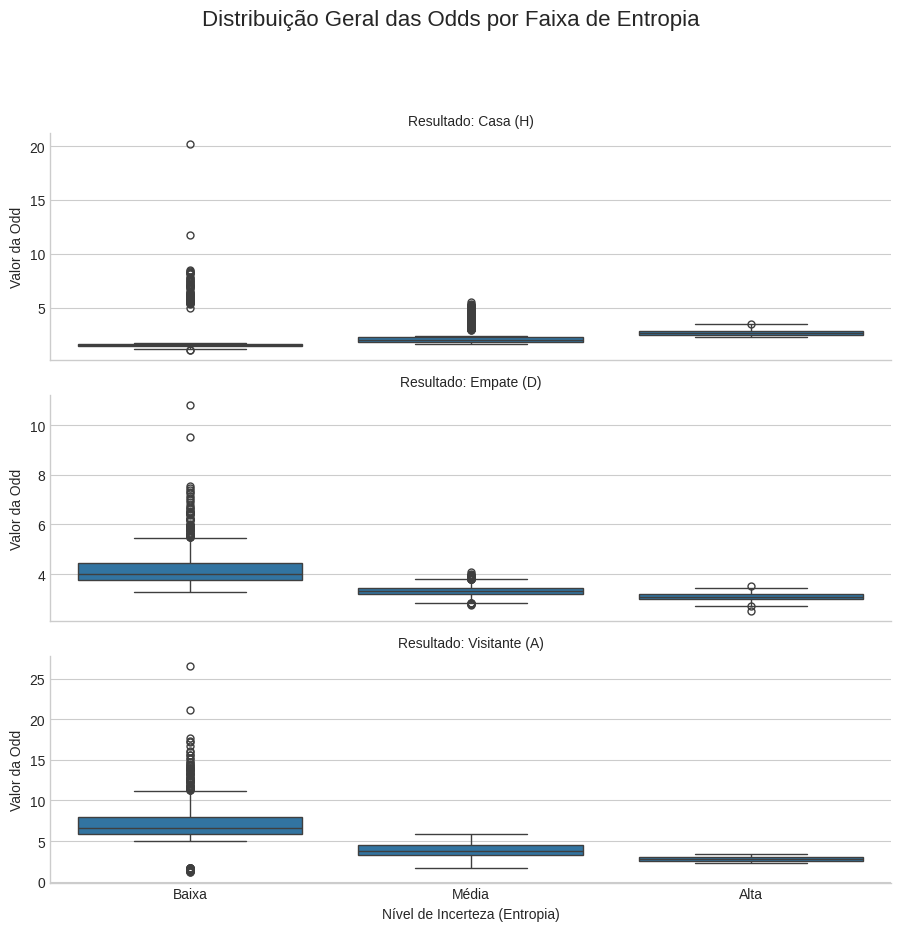

In [ ]:
# Usamos catplot, que é ideal para criar uma grade de gráficos categóricos
g = sns.catplot(
    data=df_melted,
    x='faixa_entropia',
    y='Valor da Odd',
    row='Tipo de Odd',  # Cria uma linha de gráficos para cada tipo de odd
    kind='box',         # Especifica que queremos boxplots
    order=['Baixa', 'Média', 'Alta'], # Garante a ordem do eixo X
    row_order=['Casa (H)', 'Empate (D)', 'Visitante (A)'], # Garante a ordem das linhas
    height=3,           # Altura de cada subplot
    aspect=3,           # Proporção largura/altura
    sharey=False        # Cada subplot terá sua própria escala Y, o que é essencial aqui
)

g.fig.suptitle('Distribuição Geral das Odds por Faixa de Entropia', y=1.03, fontsize=16)
g.set_axis_labels("Nível de Incerteza (Entropia)", "Valor da Odd")
g.set_titles("Resultado: {row_name}") # Título para cada linha
plt.tight_layout(rect=[0, 0, 1, 0.97]) # Ajusta layout para o suptitle
plt.show()

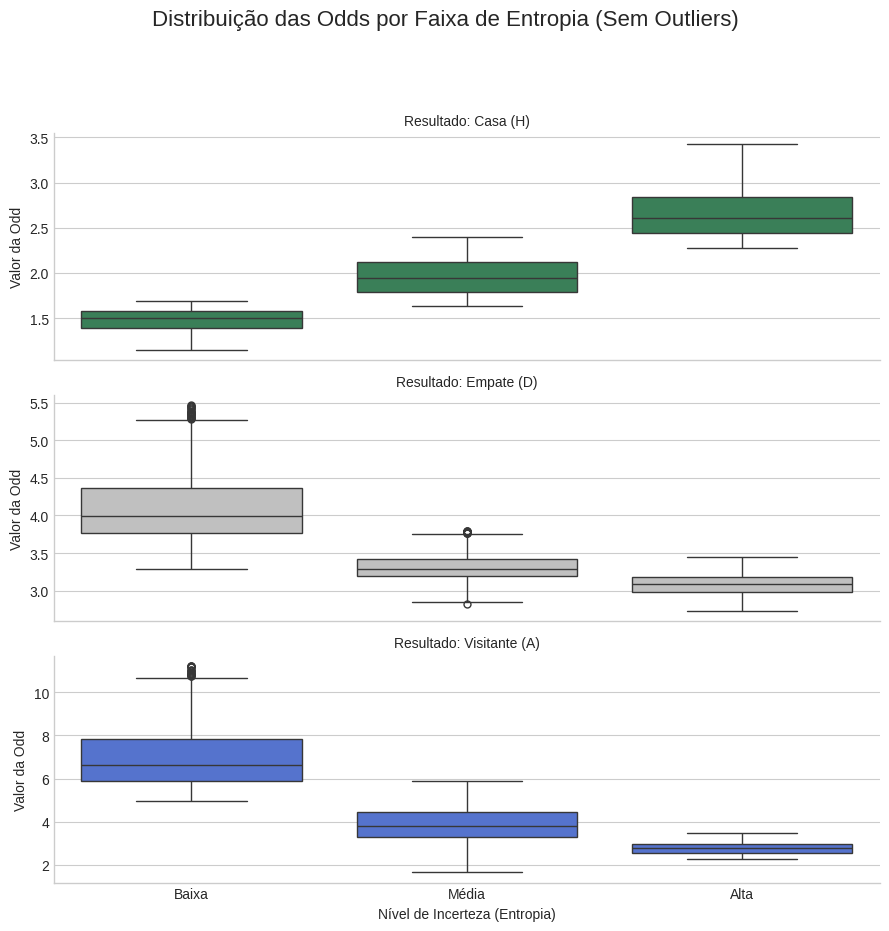

In [ ]:
# --- Preparação dos dados (código inalterado) ---
df_plot = df[['faixa_entropia', 'AvgCH', 'AvgCD', 'AvgCA']]
df_melted = df_plot.melt(
    id_vars=['faixa_entropia'],
    value_vars=['AvgCH', 'AvgCD', 'AvgCA'],
    var_name='Tipo de Odd',
    value_name='Valor da Odd'
)
label_map = {'AvgCH': 'Casa (H)', 'AvgCD': 'Empate (D)', 'AvgCA': 'Visitante (A)'}
df_melted['Tipo de Odd'] = df_melted['Tipo de Odd'].map(label_map)

# --- Filtrando outliers (código inalterado) ---
Q1 = df_melted.groupby(['Tipo de Odd', 'faixa_entropia'], observed=True)['Valor da Odd'].quantile(0.25)
Q3 = df_melted.groupby(['Tipo de Odd', 'faixa_entropia'], observed=True)['Valor da Odd'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
limite_inferior = Q1 - 1.5 * IQR
limites_df = pd.DataFrame({'Limite_Superior': limite_superior, 'Limite_Inferior': limite_inferior}).reset_index()
df_melted_com_limites = pd.merge(df_melted, limites_df, on=['Tipo de Odd', 'faixa_entropia'])
dentro_dos_limites = (
    (df_melted_com_limites['Valor da Odd'] <= df_melted_com_limites['Limite_Superior']) &
    (df_melted_com_limites['Valor da Odd'] >= df_melted_com_limites['Limite_Inferior'])
)
df_sem_outliers = df_melted_com_limites[dentro_dos_limites]

# --- CORREÇÃO NA PLOTAGEM ---

# Define a paleta de cores para os Tipos de Odd
cores_odds = {
    'Casa (H)': 'seagreen',
    'Empate (D)': 'silver',
    'Visitante (A)': 'royalblue'
}

g = sns.catplot(
    data=df_sem_outliers,
    x='faixa_entropia',
    y='Valor da Odd',
    row='Tipo de Odd',
    kind='box',
    order=['Baixa', 'Média', 'Alta'],
    row_order=['Casa (H)', 'Empate (D)', 'Visitante (A)'],
    height=3,
    aspect=3,
    sharey=False,
    # --- Aqui está a mudança principal ---
    hue='Tipo de Odd',        # Define que a cor é baseada no Tipo de Odd
    palette=cores_odds,       # Fornece o dicionário de cores correto
    legend=False              # A legenda é redundante pois já temos os títulos das linhas
)

g.fig.suptitle('Distribuição das Odds por Faixa de Entropia (Sem Outliers)', y=1.03, fontsize=16)
g.set_axis_labels("Nível de Incerteza (Entropia)", "Valor da Odd")
g.set_titles("Resultado: {row_name}")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

/tmp/ipython-input-2195809398.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_segmento['bin'] = pd.cut(df_segmento[odd_col], bins=bins, right=False)
/tmp/ipython-input-2195809398.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_segmento['bin'] = pd.cut(df_segmento[odd_col], bins=bins, right=False)
/tmp/ipython-input-2195809398.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cave

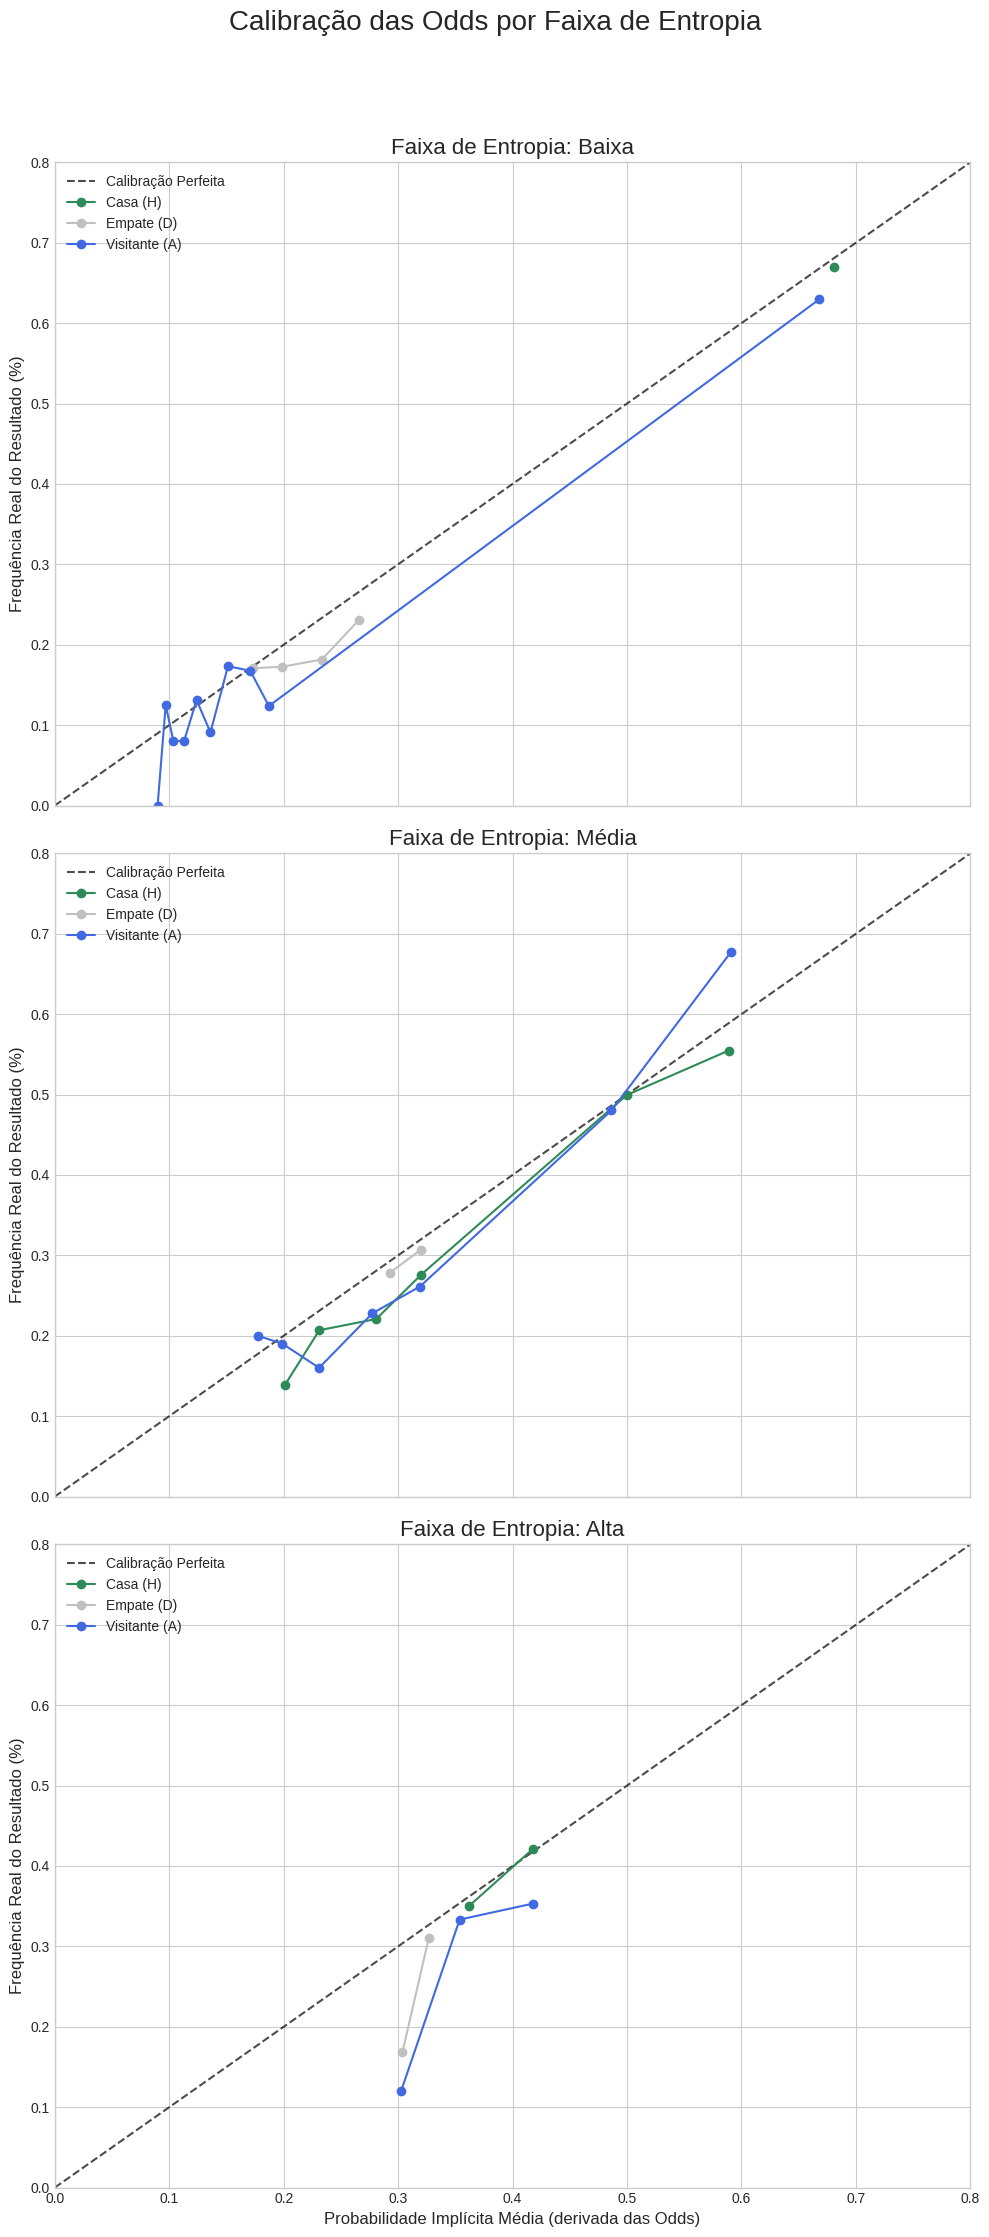

In [ ]:
# --- ETAPA 1: Preparar os dados (uma única vez) ---
# Cria um DataFrame de trabalho com todas as colunas necessárias
df_analise = df[['Res', 'AvgCH', 'AvgCD', 'AvgCA', 'faixa_entropia']].copy()

# Calcula as probabilidades implícitas para todos os jogos
df_analise['ProbH'] = 1 / df_analise['AvgCH']
df_analise['ProbD'] = 1 / df_analise['AvgCD']
df_analise['ProbA'] = 1 / df_analise['AvgCA']

# --- ETAPA 2: Configurar a estrutura do gráfico ---
# Cria uma figura com 3 linhas e 1 coluna de subplots
# sharex e sharey garantem que todos os gráficos tenham a mesma escala para fácil comparação
fig, axes = plt.subplots(3, 1, figsize=(10, 24), sharex=True, sharey=True)
fig.suptitle('Calibração das Odds por Faixa de Entropia', fontsize=20, y=0.93)

# Dicionários para iteração e plotagem
outcomes = {'H': 'AvgCH', 'D': 'AvgCD', 'A': 'AvgCA'}
cores = {'H': 'seagreen', 'D': 'silver', 'A': 'royalblue'}
nomes = {'H': 'Casa (H)', 'D': 'Empate (D)', 'A': 'Visitante (A)'}

# --- ETAPA 3: Loop sobre cada faixa de entropia para gerar cada subplot ---
for i, segmento in enumerate(['Baixa', 'Média', 'Alta']):
    ax = axes[i] # Seleciona o subplot atual (0, 1, ou 2)

    # Filtra o DataFrame para conter apenas os jogos do segmento atual
    df_segmento = df_analise[df_analise['faixa_entropia'] == segmento]

    ax.set_title(f'Faixa de Entropia: {segmento}', fontsize=16)

    # Linha de calibração perfeita
    ax.plot([0, 1], [0, 1], 'k--', label='Calibração Perfeita', alpha=0.7)

    # Loop para calcular e plotar a calibração para H, D, e A dentro do segmento
    for outcome_char, odd_col in outcomes.items():
        # Cria as faixas de odds (bins)
        bins = np.arange(1, 15, 0.75)
        df_segmento['bin'] = pd.cut(df_segmento[odd_col], bins=bins, right=False)

        grouped = df_segmento.groupby('bin', observed=True)

        calibracao = grouped.agg(
            total_jogos=('Res', 'count'),
            prob_implicita_media=(f'Prob{outcome_char}', 'mean'),
            frequencia_real=('Res', lambda x: (x == outcome_char).mean())
        ).reset_index()

        # Filtra faixas com poucos jogos para ter uma estatística mais robusta
        # Usamos um limite menor aqui, pois os dados estão segmentados
        df_plot = calibracao[calibracao['total_jogos'] > 20].dropna()

        if not df_plot.empty:
            ax.plot(
                df_plot['prob_implicita_media'],
                df_plot['frequencia_real'],
                marker='o',
                linestyle='-',
                label=nomes[outcome_char],
                color=cores[outcome_char]
            )

    # Configurações do subplot
    ax.set_ylabel('Frequência Real do Resultado (%)', fontsize=12)
    ax.grid(True)
    ax.legend()

# Configuração final do eixo X (apenas no último gráfico)
axes[-1].set_xlabel('Probabilidade Implícita Média (derivada das Odds)', fontsize=12)
axes[-1].set_xlim(0, 0.8)
axes[-1].set_ylim(0, 0.8)

plt.tight_layout(rect=[0, 0, 1, 0.9]) # Ajusta o layout para o suptitle
plt.show()

In [ ]:
# --- ETAPA 1: Preparar os dados (uma única vez) ---
df_analise = df[['Res', 'AvgCH', 'AvgCD', 'AvgCA', 'faixa_entropia']].copy()
df_analise['ProbH'] = 1 / df_analise['AvgCH']
df_analise['ProbD'] = 1 / df_analise['AvgCD']
df_analise['ProbA'] = 1 / df_analise['AvgCA']

# Dicionários para ajudar na iteração
outcomes = {'H': ('AvgCH', 'ProbH'), 'D': ('AvgCD', 'ProbD'), 'A': ('AvgCA', 'ProbA')}
nomes = {'H': 'Casa (H)', 'D': 'Empate (D)', 'A': 'Visitante (A)'}

# Lista para coletar todos os resultados dos testes
resultados_finais = []

# --- ETAPA 2: Loop para coletar todos os resultados ---
for segmento in ['Baixa', 'Média', 'Alta']:
    df_segmento_base = df_analise[df_analise['faixa_entropia'] == segmento].copy()

    for outcome_char, (odd_col, prob_col) in outcomes.items():
        df_segmento = df_segmento_base.copy()

        bins = np.arange(1, 25, 1.0)
        df_segmento['bin'] = pd.cut(df_segmento[odd_col], bins=bins, right=False)

        grouped = df_segmento.groupby('bin', observed=True)
        calibracao = grouped.agg(
            total_jogos=('Res', 'count'),
            jogos_vencidos=('Res', lambda x: (x == outcome_char).sum()),
            prob_implicita_media=(prob_col, 'mean')
        ).reset_index()

        df_teste = calibracao[calibracao['total_jogos'] > 20].dropna().copy()

        for index, row in df_teste.iterrows():
            teste_resultado = binomtest(k=row['jogos_vencidos'], n=row['total_jogos'], p=row['prob_implicita_media'])
            # Coleta todos os dados relevantes em um dicionário
            resultados_finais.append({
                'Faixa Entropia': segmento,
                'Resultado': nomes[outcome_char],
                'Faixa de Odds': str(row['bin']),
                'Nº Jogos': int(row['total_jogos']),
                'Previsto (%)': row['prob_implicita_media'],
                'Realizado (%)': row['jogos_vencidos'] / row['total_jogos'],
                'p_value': teste_resultado.pvalue
            })

# --- ETAPA 3: Filtrar e apresentar a conclusão objetiva ---
# Converte a lista de resultados em um DataFrame
df_resultados_completos = pd.DataFrame(resultados_finais)

# Define as condições para encontrar valor
condicao_significancia = df_resultados_completos['p_value'] < 0.05
condicao_subestimacao = df_resultados_completos['Realizado (%)'] > df_resultados_completos['Previsto (%)']

# Aplica o filtro final
oportunidades_de_valor = df_resultados_completos[condicao_significancia & condicao_subestimacao]

# Apresenta o resultado final
print("="*80)
print("CONCLUSÃO: OPORTUNIDADES DE VALOR ESTATISTICAMENTE SIGNIFICATIVAS")
print("="*80)
print("Cenários onde o mercado SUBESTIMOU a probabilidade real de um evento:\n")

if oportunidades_de_valor.empty:
    print("Nenhuma oportunidade de valor estatisticamente significativa foi encontrada nos dados.")
else:
    # Formata o DataFrame para melhor visualização
    display(oportunidades_de_valor.style.format({
        'Nº Jogos': '{:d}',
        'Previsto (%)': '{:.2%}',
        'Realizado (%)': '{:.2%}',
        'p_value': '{:.4f}'
    }))

CONCLUSÃO: OPORTUNIDADES DE VALOR ESTATISTICAMENTE SIGNIFICATIVAS
Cenários onde o mercado SUBESTIMOU a probabilidade real de um evento:

Nenhuma oportunidade de valor estatisticamente significativa foi encontrada nos dados.


**O Que Este Resultado Realmente Significa**

Dentro deste conjunto de dados de 5148 jogos, não existe nenhum cenário repetível e claramente definido (por faixa de entropia e faixa de odds) onde a casa de apostas tenha subestimado a probabilidade de um resultado de forma estatisticamente significativa.
Em outras palavras, não há "dinheiro fácil" ou uma falha óbvia no sistema que possa ser explorada de forma consistente.

In [ ]:
# --- Verificação Inicial ---
print(f"Tamanho total do DataFrame original: {df.shape}")
print("-" * 40)

# --- ETAPA 1: Criar o DataFrame para Baixa Entropia ---
# Filtra as linhas onde a faixa_entropia é 'Baixa'
# .copy() é importante para criar um DataFrame independente e evitar warnings futuros
df_baixa = df[df['faixa_entropia'] == 'Baixa'].copy()

# --- ETAPA 2: Criar o DataFrame para Média Entropia ---
# Filtra as linhas onde a faixa_entropia é 'Média'
df_media = df[df['faixa_entropia'] == 'Média'].copy()

# --- ETAPA 3: Criar o DataFrame para Alta Entropia ---
# Filtra as linhas onde a faixa_entropia é 'Alta'
df_alta = df[df['faixa_entropia'] == 'Alta'].copy()


# --- ETAPA 4: Verificar se a separação foi bem-sucedida ---
print("Verificação dos novos DataFrames:\n")

# Verifica o tamanho de cada novo DataFrame
print(f"Tamanho do df_baixa: {df_baixa.shape}")
print(f"Tamanho do df_media: {df_media.shape}")
print(f"Tamanho do df_alta:  {df_alta.shape}")
print("-" * 40)

# Verifica se a soma das partes é igual ao todo (nenhum dado foi perdido)
total_separado = len(df_baixa) + len(df_media) + len(df_alta)
print(f"Soma das linhas dos novos DFs: {total_separado}")
print(f"As contagens correspondem ao original? {'Sim' if total_separado == len(df) else 'Não'}")
print("-" * 40)

# Visualiza a cabeça de um dos novos DataFrames para confirmar o conteúdo
print("Exemplo de conteúdo do df_baixa (5 primeiras linhas):")
display(df_baixa.head())

Tamanho total do DataFrame original: (5148, 9)
----------------------------------------
Verificação dos novos DataFrames:

Tamanho do df_baixa: (1287, 9)
Tamanho do df_media: (2574, 9)
Tamanho do df_alta:  (1287, 9)
----------------------------------------
Soma das linhas dos novos DFs: 5148
As contagens correspondem ao original? Sim
----------------------------------------
Exemplo de conteúdo do df_baixa (5 primeiras linhas):


,Date,Home,Away,Res,AvgCH,AvgCD,AvgCA,entropy,faixa_entropia
2,2012-05-20,Figueirense,Nautico,H,1.59,3.67,5.64,1.383406,Baixa
15,2012-05-27,Santos,Sport Recife,D,1.41,4.17,7.46,1.254669,Baixa
16,2012-05-27,Sao Paulo,Bahia,H,1.44,4.12,6.93,1.281885,Baixa
23,2012-06-07,Atletico-MG,Bahia,D,1.43,4.13,7.23,1.269322,Baixa
24,2012-06-07,Coritiba,Portuguesa,H,1.59,3.72,5.37,1.391111,Baixa


In [ ]:
# Exportando os resultados para o Excel
df_baixa.to_excel('jogos_baixa_entropia.xlsx', index=False)
df_media.to_excel('jogos_media_entropia.xlsx', index=False)
df_alta.to_excel('jogos_alta_entropia.xlsx', index=False)